In [2]:
!pip install -q google-api-python-client transformers emoji wordcloud
print("Installed")

Installed


In [5]:
from googleapiclient.discovery import build
from googleapiclient.errors import HttpError
import pandas as pd, re

API_KEY = "YAHAN_APNI_KEY_PASTE_KARO"
BRAND = "Daraz"
yt = build("youtube", "v3", developerKey=API_KEY)

def search_videos(q, pages=2):
    ids, token = [], None
    for _ in range(pages):
        try:
            params = dict(q=q, part="id", type="video", regionCode="PK", maxResults=50)
            if token:
                params["pageToken"] = token
            r = yt.search().list(**params).execute()
        except HttpError as e:
            print("Search error:", str(e)[:300])
            break
        for i in r.get("items", []):
            vid = i.get("id", {}).get("videoId")
            if vid:
                ids.append(vid)
        token = r.get("nextPageToken")
        if not token:
            break
    return ids

queries = [BRAND, f"{BRAND} Pakistan", f"{BRAND} ad", f"{BRAND} review",
           f"{BRAND} complaint", f"{BRAND} sale"]
video_ids = list({v for q in queries for v in search_videos(q)})
print("Videos mile:", len(video_ids))

def dur_sec(d):
    m = re.match(r'PT(?:(\d+)H)?(?:(\d+)M)?(?:(\d+)S)?', d)
    h, mi, s = [int(x or 0) for x in m.groups()]
    return h*3600 + mi*60 + s

rows = []
for i in range(0, len(video_ids), 50):
    r = yt.videos().list(part="snippet,statistics,contentDetails",
                         id=",".join(video_ids[i:i+50])).execute()
    for v in r.get("items", []):
        s, st = v["snippet"], v.get("statistics", {})
        rows.append({"video_id": v["id"], "title": s["title"],
            "channel": s["channelTitle"], "description": s.get("description", ""),
            "video_time": s["publishedAt"],
            "duration": dur_sec(v["contentDetails"]["duration"]),
            "views": int(st.get("viewCount", 0)),
            "likes": int(st.get("likeCount", 0)),
            "n_comments": int(st.get("commentCount", 0))})
videos = pd.DataFrame(rows)

mask = videos.title.str.contains(BRAND, case=False) | videos.channel.str.contains(BRAND, case=False)
videos = videos[mask].sort_values("n_comments", ascending=False).head(60).reset_index(drop=True)
print("Brand videos:", len(videos))

def get_comments(vid, max_c=200):
    out, token = [], None
    while len(out) < max_c:
        try:
            params = dict(part="snippet", videoId=vid, maxResults=100, textFormat="plainText")
            if token:
                params["pageToken"] = token
            r = yt.commentThreads().list(**params).execute()
        except HttpError:
            break
        for it in r.get("items", []):
            s = it["snippet"]["topLevelComment"]["snippet"]
            out.append({"video_id": vid, "comment": s["textDisplay"],
                        "comment_likes": s["likeCount"],
                        "replies": it["snippet"]["totalReplyCount"],
                        "comment_time": s["publishedAt"]})
        token = r.get("nextPageToken")
        if not token:
            break
    return out

all_c = []
for vid in videos.video_id:
    all_c += get_comments(vid)
comments = pd.DataFrame(all_c)
df = comments.merge(videos, on="video_id")
print("Total comments:", len(df))
df.to_csv("raw_data.csv", index=False)
df.head()

Videos mile: 419
Brand videos: 60
Total comments: 7939


,video_id,comment,comment_likes,replies,comment_time,title,channel,description,video_time,duration,views,likes,n_comments
0,rkUI8HPZ-jU,بھت ھی بھتر انداز اور تفصئل سے سمجھاتے ھیں ۔شکریہ,1,1,2026-10-19T04:28:31Z,Daraz Course | Daraz Affiliate Program in Paki...,Learning and Earning with Anjum Iqbal,Daraz Course | Daraz Affiliate Program in Paki...,2023-11-12T14:37:00Z,1042,201551,9776,1999
1,rkUI8HPZ-jU,sir plz replay kren \nmai affiliate ka account...,1,2,2026-10-18T13:23:21Z,Daraz Course | Daraz Affiliate Program in Paki...,Learning and Earning with Anjum Iqbal,Daraz Course | Daraz Affiliate Program in Paki...,2023-11-12T14:37:00Z,1042,201551,9776,1999
2,rkUI8HPZ-jU,adds chala kar,0,0,2026-10-16T06:31:08Z,Daraz Course | Daraz Affiliate Program in Paki...,Learning and Earning with Anjum Iqbal,Daraz Course | Daraz Affiliate Program in Paki...,2023-11-12T14:37:00Z,1042,201551,9776,1999
3,rkUI8HPZ-jU,Good,1,0,2026-10-11T18:03:27Z,Daraz Course | Daraz Affiliate Program in Paki...,Learning and Earning with Anjum Iqbal,Daraz Course | Daraz Affiliate Program in Paki...,2023-11-12T14:37:00Z,1042,201551,9776,1999
4,rkUI8HPZ-jU,Very good,1,1,2026-10-11T13:55:58Z,Daraz Course | Daraz Affiliate Program in Paki...,Learning and Earning with Anjum Iqbal,Daraz Course | Daraz Affiliate Program in Paki...,2023-11-12T14:37:00Z,1042,201551,9776,1999


In [6]:
import emoji

NORMALIZE = {"accha":"acha","achaa":"acha","bht":"bohat","boht":"bohat","bohot":"bohat",
             "mahnga":"mehnga","mehngi":"mehnga","bekaar":"bekar","zabrdast":"zabardast"}

def clean(t):
    t = str(t).lower()
    t = re.sub(r"http\S+|www\S+", "", t)
    t = emoji.demojize(t, delimiters=(" ", " "))
    t = re.sub(r"[^\w\s\u0600-\u06FF]", " ", t)
    return " ".join(NORMALIZE.get(w, w) for w in t.split())

def lang(t):
    if re.search(r"[\u0600-\u06FF]", t):
        return "Urdu"
    roman = {"hai","nahi","bohat","acha","kya","ka","ki","mein","bhai","yaar","ho","hain","ko","sir","kren","kro","kar","se","ap","aap","mai","main"}
    if roman & set(t.split()):
        return "Roman Urdu"
    return "English"

df["clean_text"] = df.comment.apply(clean)
df = df[df.clean_text.str.len() > 2].reset_index(drop=True)
df["language"] = df.clean_text.apply(lang)

df["comment_time"] = pd.to_datetime(df.comment_time, utc=True).dt.tz_convert("Asia/Karachi")
df["hour"] = df.comment_time.dt.hour
df["day"] = df.comment_time.dt.day_name()
df["engagement"] = df.comment_likes + df.replies
df["hashtags"] = (df.title + " " + df.description).str.findall(r"#\w+")

print("Cleaned comments:", len(df))
print(df.language.value_counts())
df[["comment", "clean_text", "language", "hour", "day", "engagement"]].head(10)

Cleaned comments: 7888
language
English       4224
Roman Urdu    3444
Urdu           220
Name: count, dtype: int64


,comment,clean_text,language,hour,day,engagement
0,بھت ھی بھتر انداز اور تفصئل سے سمجھاتے ھیں ۔شکریہ,بھت ھی بھتر انداز اور تفصئل سے سمجھاتے ھیں ۔شکریہ,Urdu,9,Monday,2
1,sir plz replay kren \nmai affiliate ka account...,sir plz replay kren mai affiliate ka account b...,Roman Urdu,18,Sunday,3
2,adds chala kar,adds chala kar,Roman Urdu,11,Friday,0
3,Good,good,English,23,Sunday,1
4,Very good,very good,English,18,Sunday,2
5,Aap ek hi video mein Kyon Nahin batate acchi h...,aap ek hi video mein kyon nahin batate acchi h...,Roman Urdu,16,Wednesday,0
6,Draz affiliate program,draz affiliate program,English,1,Saturday,0
7,Marketing,marketing,English,21,Friday,1
8,Daraz india ma nahi hai kiya sir?,daraz india ma nahi hai kiya sir,Roman Urdu,15,Wednesday,0
9,Jazzcash account nh attach krsktese? agr bank...,jazzcash account nh attach krsktese agr bank a...,Roman Urdu,16,Monday,0


In [7]:
from transformers import pipeline
import torch

print("GPU mila:", torch.cuda.is_available())

clf = pipeline("sentiment-analysis",
               model="cardiffnlp/twitter-xlm-roberta-base-sentiment",
               truncation=True, max_length=128,
               device=0 if torch.cuda.is_available() else -1)

res = clf(df.clean_text.tolist(), batch_size=32)
df["sentiment"] = [r["label"].lower() for r in res]
df["confidence"] = [r["score"] for r in res]

print(df.sentiment.value_counts())
df.to_csv("final_data.csv", index=False)
df[["comment", "language", "sentiment", "confidence"]].head(10)

GPU mila: True


config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

...

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

sentiment
neutral     3518
negative    2661
positive    1709
Name: count, dtype: int64


,comment,language,sentiment,confidence
0,بھت ھی بھتر انداز اور تفصئل سے سمجھاتے ھیں ۔شکریہ,Urdu,positive,0.558303
1,sir plz replay kren \nmai affiliate ka account...,Roman Urdu,positive,0.340060
2,adds chala kar,Roman Urdu,negative,0.362632
3,Good,English,positive,0.431504
4,Very good,English,positive,0.715242
5,Aap ek hi video mein Kyon Nahin batate acchi h...,Roman Urdu,negative,0.370775
6,Draz affiliate program,English,neutral,0.667655
7,Marketing,English,neutral,0.411201
8,Daraz india ma nahi hai kiya sir?,Roman Urdu,negative,0.444315
9,Jazzcash account nh attach krsktese? agr bank...,Roman Urdu,negative,0.405005


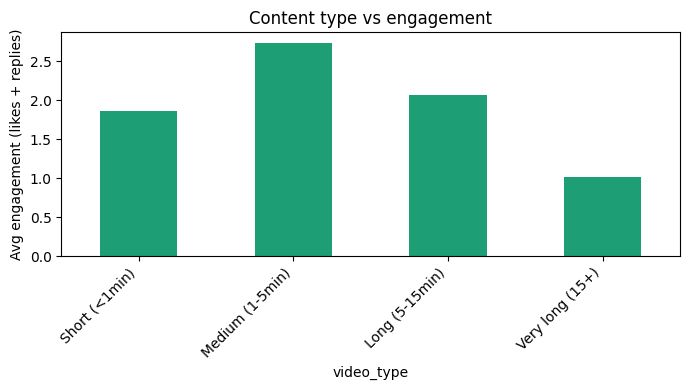

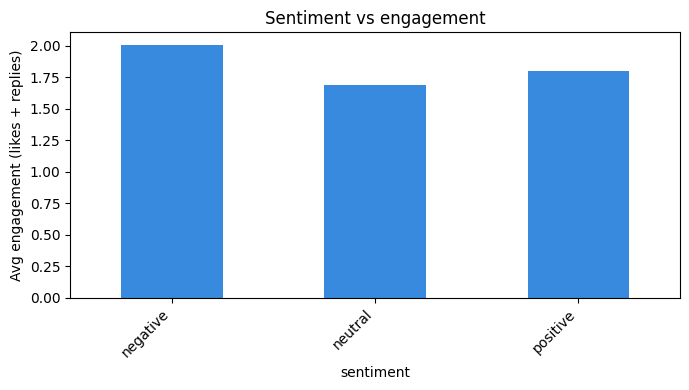

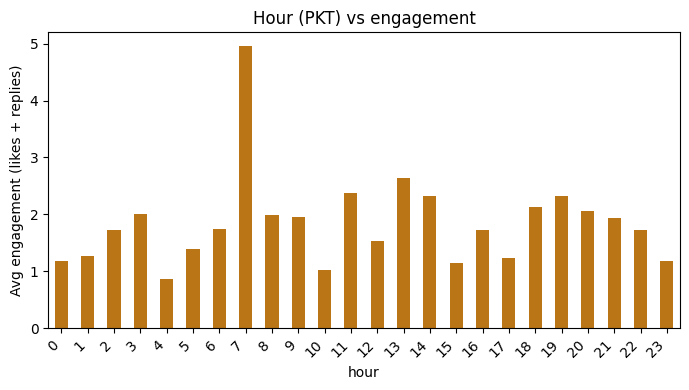

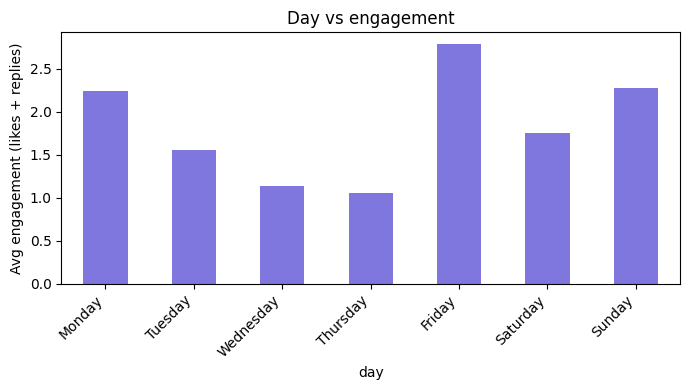

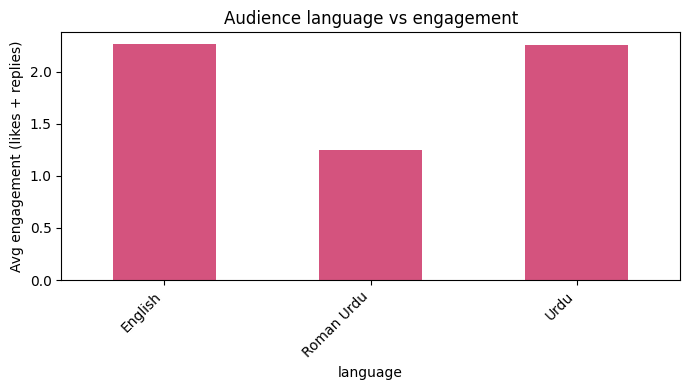

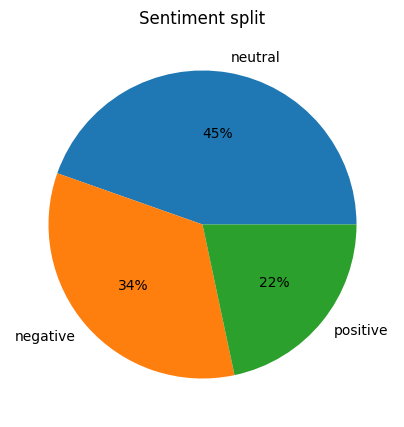

Top hashtags: [('#daraz', 23), ('#shorts', 13), ('#darazcourse', 6), ('#business', 6), ('#ecommerce', 6), ('#youtubeshorts', 5), ('#unboxing', 5), ('#darazselleraccount', 4), ('#entrepreneur', 3), ('#millionaire', 3)]
channel
Glow up with Mahnoor      9
Learn with Fawaz Ahmed    6
Digital Setup             3
Azad Chaiwala             3
Daraz Nepal               2
Name: count, dtype: int64


In [8]:
import matplotlib.pyplot as plt
from collections import Counter

def bar(series, title, color="#1D9E75"):
    series.plot(kind="bar", figsize=(7,4), title=title, color=color)
    plt.ylabel("Avg engagement (likes + replies)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# Chart 1: Content type (video length)
df["video_type"] = pd.cut(df.duration, [0,60,300,900,100000],
                          labels=["Short (<1min)","Medium (1-5min)","Long (5-15min)","Very long (15+)"])
bar(df.groupby("video_type", observed=True).engagement.mean(), "Content type vs engagement")

# Chart 2: Sentiment vs engagement
bar(df.groupby("sentiment").engagement.mean(), "Sentiment vs engagement", "#378ADD")

# Chart 3: Hour of day (PKT)
bar(df.groupby("hour").engagement.mean(), "Hour (PKT) vs engagement", "#BA7517")

# Chart 4: Day of week
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
bar(df.groupby("day").engagement.mean().reindex(order), "Day vs engagement", "#7F77DD")

# Chart 5: Audience language
bar(df.groupby("language").engagement.mean(), "Audience language vs engagement", "#D4537E")

# Chart 6: Sentiment split
df.sentiment.value_counts().plot(kind="pie", autopct="%1.0f%%", figsize=(5,5),
                                 title="Sentiment split", ylabel="")
plt.show()

# Hashtags
tags = Counter(t.lower() for lst in df.drop_duplicates("video_id").hashtags for t in lst)
print("Top hashtags:", tags.most_common(10))

# Top channels
print(df.drop_duplicates("video_id").channel.value_counts().head(5))

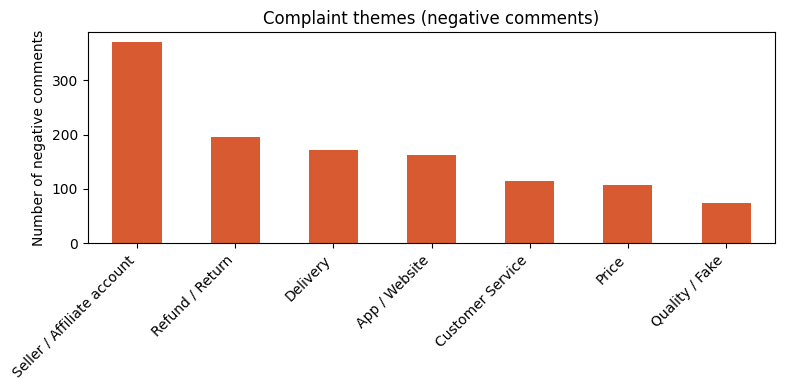

Seller / Affiliate account    370
Refund / Return               195
Delivery                      171
App / Website                 162
Customer Service              114
Price                         108
Quality / Fake                 74
dtype: int64

INSIGHTS: {'brand': 'Daraz', 'best_content_type': 'Medium (1-5min)', 'best_hour': 7, 'best_day': 'Friday', 'best_language': 'English', 'top_sentiment_for_engagement': 'negative', 'top_hashtags': ['#daraz', '#shorts', '#darazcourse', '#business', '#ecommerce'], 'top_complaints': ['Seller / Affiliate account', 'Refund / Return', 'Delivery']}

RECOMMENDATION FOR Daraz
1. Content: Medium (1-5min) videos par sab se zyada engagement mili.
2. Timing: Friday ko, 7:00 PKT ke aas paas post karein.
3. Language: English mein caption aur replies likhein, audience isi mein zyada active hai.
4. Hashtags: #daraz, #shorts, #darazcourse, #business, #ecommerce use karein.
5. Sab se pehle fix karein: Seller / Affiliate account, Refund / Return, Delivery, kyu

In [9]:
neg = df[df.sentiment == "negative"]

THEMES = {
 "Delivery":          ["delivery","deliver","late","delay","courier","rider","parcel"],
 "Price":             ["price","mehnga","expensive","costly","qeemat","rate","sasta"],
 "Quality / Fake":    ["quality","fake","duplicate","asli","nakli","bekar","kharab","broken","original"],
 "Refund / Return":   ["refund","return","paisa","paise","wapis","cancel","replace"],
 "Customer Service":  ["customer","service","support","helpline","complaint","response","reply","jawab"],
 "App / Website":     ["app","website","login","crash","error","glitch","otp"],
 "Seller / Affiliate account": ["affiliate","seller","account","approve","commission","payment","jazzcash","bank","verification"],
}
theme_count = {k: int(neg.clean_text.apply(lambda t: any(w in t.split() or w in t for w in kws)).sum())
               for k, kws in THEMES.items()}
theme_series = pd.Series(theme_count).sort_values(ascending=False)

theme_series.plot(kind="bar", color="#D85A30", figsize=(8,4),
                  title="Complaint themes (negative comments)")
plt.ylabel("Number of negative comments")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
print(theme_series)

# Insights
best = lambda col: df.groupby(col, observed=True).engagement.mean().idxmax()
insights = {
  "brand": BRAND,
  "best_content_type": str(best("video_type")),
  "best_hour": int(best("hour")),
  "best_day": best("day"),
  "best_language": best("language"),
  "top_sentiment_for_engagement": best("sentiment"),
  "top_hashtags": [t for t, _ in tags.most_common(5)],
  "top_complaints": theme_series.head(3).index.tolist(),
}
print("\nINSIGHTS:", insights)

print(f"""
RECOMMENDATION FOR {BRAND}
1. Content: {insights['best_content_type']} videos par sab se zyada engagement mili.
2. Timing: {insights['best_day']} ko, {insights['best_hour']}:00 PKT ke aas paas post karein.
3. Language: {insights['best_language']} mein caption aur replies likhein, audience isi mein zyada active hai.
4. Hashtags: {', '.join(insights['top_hashtags'])} use karein.
5. Sab se pehle fix karein: {', '.join(insights['top_complaints'])}, kyunke negative comments ka bara hissa inhi ke baare mein hai.
6. Sentiment: {insights['top_sentiment_for_engagement']} comments par sab se zyada engagement aati hai, is liye in comments ko jaldi reply karein.
""")

In [10]:
!pip install -q pyspark
from pyspark.sql import SparkSession, functions as F

spark = SparkSession.builder.appName("PKContentDetective").getOrCreate()
sdf = spark.read.csv("final_data.csv", header=True, inferSchema=True,
                     multiLine=True, escape='"')

print("Total rows in Spark:", sdf.count())

print("--- Sentiment vs engagement ---")
sdf.groupBy("sentiment").agg(F.count("*").alias("comments"),
                             F.round(F.avg("engagement"), 2).alias("avg_engagement")).show()

print("--- Language segments ---")
sdf.groupBy("language").agg(F.count("*").alias("comments"),
                            F.round(F.avg("engagement"), 2).alias("avg_engagement")).show()

print("--- Best hours (PKT) ---")
sdf.groupBy("hour").agg(F.round(F.avg("engagement"), 2).alias("avg_engagement")) \
   .orderBy(F.desc("avg_engagement")).show(5)

print("--- Best days ---")
sdf.groupBy("day").agg(F.round(F.avg("engagement"), 2).alias("avg_engagement")) \
   .orderBy(F.desc("avg_engagement")).show()

Total rows in Spark: 7888
--- Sentiment vs engagement ---
+---------+--------+--------------+
|sentiment|comments|avg_engagement|
+---------+--------+--------------+
| positive|    1709|           1.8|
|  neutral|    3518|          1.69|
| negative|    2661|           2.0|
+---------+--------+--------------+

--- Language segments ---
+----------+--------+--------------+
|  language|comments|avg_engagement|
+----------+--------+--------------+
|      Urdu|     220|          2.25|
|Roman Urdu|    3444|          1.25|
|   English|    4224|          2.26|
+----------+--------+--------------+

--- Best hours (PKT) ---
+----+--------------+
|hour|avg_engagement|
+----+--------------+
|   7|          4.95|
|  13|          2.63|
|  11|          2.38|
|  19|          2.32|
|  14|          2.32|
+----+--------------+
only showing top 5 rows
--- Best days ---
+---------+--------------+
|      day|avg_engagement|
+---------+--------------+
|   Friday|          2.79|
|   Sunday|          2.28|
|  